# 05 · Solution 3: Genetic Algorithm (metaheuristic) + Multilayer Perceptron

### Feature selection: Genetic Algorithm (GA)
MI and RFE both *rank* features and keep the top k. A GA instead searches directly over **subsets**, so it can find combinations that no ranking would produce. The GA is our own implementation (`src/ser/ga_selector.py`), so every step can be explained:

| GA concept | In our problem |
|---|---|
| Chromosome | A 190-bit mask: 1 = feature used, 0 = dropped |
| Population | 20 masks; first generation random, each with 20–60 % of the features switched on |
| Fitness | Mean macro-F1 of an MLP over 3 actor-wise inner folds − 0.02 × (fraction of features used) |
| Selection | Tournament of 3: the fittest of three random masks becomes a parent |
| Crossover | Uniform: each bit is copied from either parent with probability ½ (rate 0.9) |
| Mutation | Each bit flips with probability 1.5 / 190 |
| Elitism | The 2 best masks pass unchanged to the next generation |
| Stopping | 20 generations, or earlier if the best fitness hasn't improved for 6 generations |

The small size penalty means that, between two subsets with almost the same F1, the GA prefers the smaller one.

### Classifier: Multilayer Perceptron (MLP)
A feed-forward neural network with ReLU hidden layers and a softmax output, trained with Adam on cross-entropy loss with L2 regularisation (α). Early stopping holds back a random 15 % of the training clips and stops when validation accuracy stops improving. (This internal split is not by actor. It only decides when to stop training, and the test actors are never involved.)

### Protocol
For each of the 6 outer folds:
1. The MLP's size and α are tuned on **all** features with the actor-wise inner folds. The GA's fitness uses these settings.
2. The GA runs on the 20 training actors only.
3. The MLP's settings are tuned again on the GA's chosen subset.
4. The model is tested once on the 4 unseen actors.

All three steps reuse the same inner folds, so inner scores (including GA fitness) are somewhat optimistic. The test actors are never used, so the reported test scores are not affected.

α is searched over {0.001, 0.01, 0.1, 1, 3, 10}. With about 1,200 training clips and 190 correlated features, fairly strong regularisation is expected to help.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ser.config import EMOTION_ORDER, FEATURES_CSV, RANDOM_STATE, RESULTS_DIR
from ser.evaluation import nested_ga_cv, nested_ranked_cv, rank_all, scores
from ser.features import feature_group
from ser.ga_selector import GeneticFeatureSelector
from ser.models import MLP_GRID, make_mlp
from ser.plots import GREY, SOLUTION_COLORS, plot_confusion, plot_selection_frequency, save, set_style

set_style()
COLOR = SOLUTION_COLORS["S3: GA + MLP"]

df = pd.read_csv(FEATURES_CSV)
META = ["file", "actor", "gender", "emotion_id", "emotion", "intensity", "statement", "repetition"]
FEATURES = [c for c in df.columns if c not in META]
X, y, actors = df[FEATURES].to_numpy(), df["emotion"].to_numpy(), df["actor"].to_numpy()

# GA settings: fixed (not tuned), chosen so the notebook runs in about 20-30 min on 4 cores
GA_POP, GA_GENERATIONS = 20, 20


def make_selector(fitness_params):
    # the MLP that scores each candidate subset inside the GA, using the settings tuned in step 1
    def fitness_model():
        return make_mlp(k=None, **fitness_params)
    return GeneticFeatureSelector(fitness_model, pop_size=GA_POP, generations=GA_GENERATIONS,
                                  penalty=0.02, patience=6, n_jobs=4, random_state=RANDOM_STATE)

## 1. Baseline: MLP on all 190 features

In [2]:
base = nested_ranked_cv("Baseline MLP: all features", X, y, actors, FEATURES, rank_all, make_mlp,
                        MLP_GRID, k_grid=[len(FEATURES)], files=df.file)
base.save()
base.summary().round(3)

[Baseline MLP: all features] fold 1/6 actors [np.int64(1), np.int64(12), np.int64(15), np.int64(24)]: acc=0.579 F1=0.506 k=190 {'hidden': (256, 128), 'alpha': 10.0} (26s)


[Baseline MLP: all features] fold 2/6 actors [np.int64(6), np.int64(10), np.int64(13), np.int64(19)]: acc=0.504 F1=0.499 k=190 {'hidden': (256, 128), 'alpha': 3.0} (17s)


[Baseline MLP: all features] fold 3/6 actors [np.int64(7), np.int64(16), np.int64(20), np.int64(23)]: acc=0.579 F1=0.497 k=190 {'hidden': (256, 128), 'alpha': 10.0} (15s)


[Baseline MLP: all features] fold 4/6 actors [np.int64(4), np.int64(5), np.int64(11), np.int64(18)]: acc=0.483 F1=0.410 k=190 {'hidden': (256, 128), 'alpha': 10.0} (18s)


[Baseline MLP: all features] fold 5/6 actors [np.int64(9), np.int64(14), np.int64(21), np.int64(22)]: acc=0.454 F1=0.401 k=190 {'hidden': (256, 128), 'alpha': 10.0} (18s)


[Baseline MLP: all features] fold 6/6 actors [np.int64(2), np.int64(3), np.int64(8), np.int64(17)]: acc=0.600 F1=0.528 k=190 {'hidden': (256, 128), 'alpha': 10.0} (14s)


,accuracy,macro_f1,uar,n_features,fit_seconds
mean,0.533,0.473,0.503,190.0,1.338
std,0.060,0.054,0.055,0.0,0.408


## 2. Solution 3: GA feature selection + MLP

In [3]:
s3 = nested_ga_cv("S3: GA + MLP", X, y, actors, FEATURES, make_selector, make_mlp, MLP_GRID, files=df.file)
s3.save()
s3.history.to_csv(RESULTS_DIR / "s3_ga_history.csv", index=False)
s3.summary().round(3)

[S3: GA + MLP] fold 1/6: running GA ...


  fitness model settings (tuned on all features): {'hidden': (256, 128), 'alpha': 10.0}


  gen  0: best=0.4620 mean=0.4020 features=105 (0s)


  gen  1: best=0.4627 mean=0.4383 features=112 (25s)


  gen  2: best=0.4712 mean=0.4473 features=100 (53s)


  gen  3: best=0.4782 mean=0.4582 features=109 (82s)


... (125 outputs left out)

  gen 19: best=0.4928 mean=0.4664 features=120 (565s)


  gen 20: best=0.4928 mean=0.4677 features=120 (604s)


[S3: GA + MLP] fold 6/6 actors [np.int64(2), np.int64(3), np.int64(8), np.int64(17)]: acc=0.650 F1=0.634 features=120 {'hidden': (128,), 'alpha': 1.0} (663s)


,accuracy,macro_f1,uar,n_features,fit_seconds
mean,0.543,0.511,0.522,108.167,1.682
std,0.072,0.077,0.071,5.845,0.529


In [4]:
s3.folds[["fold", "test_actors", "accuracy", "macro_f1", "uar", "n_features", "fitness_params", "params",
          "ga_generations", "ga_evaluations", "select_seconds"]].round(3)

,fold,test_actors,accuracy,macro_f1,uar,n_features,fitness_params,params,ga_generations,ga_evaluations,select_seconds
0,0,1 12 15 24,0.604,0.577,0.578,106,"{""hidden"": [256, 128], ""alpha"": 10.0}","{""hidden"": [256, 128], ""alpha"": 3.0}",20,372,589.665
1,1,6 10 13 19,0.500,0.481,0.477,105,"{""hidden"": [256, 128], ""alpha"": 3.0}","{""hidden"": [256, 128], ""alpha"": 3.0}",20,370,704.530
2,2,7 16 20 23,0.550,0.464,0.516,106,"{""hidden"": [256, 128], ""alpha"": 10.0}","{""hidden"": [256, 128], ""alpha"": 10.0}",15,283,609.777
3,3,4 5 11 18,0.488,0.444,0.461,107,"{""hidden"": [256, 128], ""alpha"": 10.0}","{""hidden"": [128], ""alpha"": 3.0}",20,367,637.807
4,4,9 14 21 22,0.467,0.465,0.465,105,"{""hidden"": [256, 128], ""alpha"": 10.0}","{""hidden"": [256, 128], ""alpha"": 1.0}",20,370,710.468
5,5,2 3 8 17,0.650,0.634,0.637,120,"{""hidden"": [256, 128], ""alpha"": 10.0}","{""hidden"": [128], ""alpha"": 1.0}",20,371,629.977


## 3. GA convergence
Left: best and average fitness of the population in each generation (one line per outer fold). Right: size of the best subset. Typically the GA quickly drops redundant features while fitness climbs, then levels off.

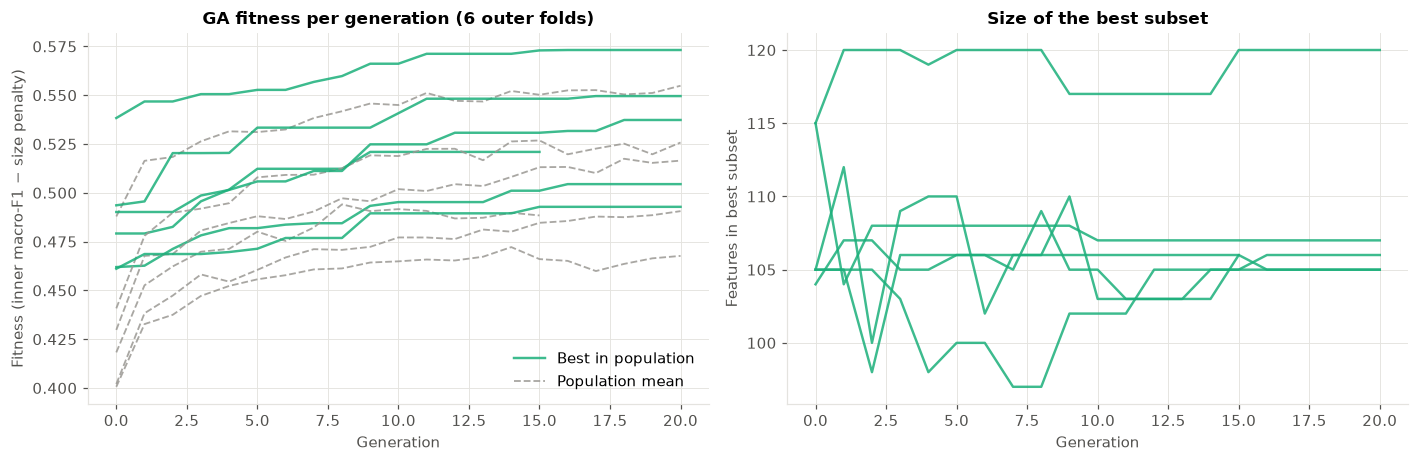

In [5]:
h = s3.history
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for f, g in h.groupby("fold"):
    axes[0].plot(g.generation, g.best_fitness, color=COLOR, lw=1.6, alpha=0.85,
                 label="Best in population" if f == 0 else None)
    axes[0].plot(g.generation, g.mean_fitness, color=GREY, lw=1.2, ls="--", alpha=0.85,
                 label="Population mean" if f == 0 else None)
    axes[1].plot(g.generation, g.best_n_features, color=COLOR, lw=1.6, alpha=0.85)
axes[0].set_xlabel("Generation"); axes[0].set_ylabel("Fitness (inner macro-F1 − size penalty)")
axes[0].set_title("GA fitness per generation (6 outer folds)")
axes[0].legend(loc="lower right")
axes[1].set_xlabel("Generation"); axes[1].set_ylabel("Features in best subset")
axes[1].set_title("Size of the best subset")
fig.tight_layout()
save(fig, "09_s3_ga_convergence")
plt.show()

## 4. Confusion matrix (out-of-fold, unseen actors)

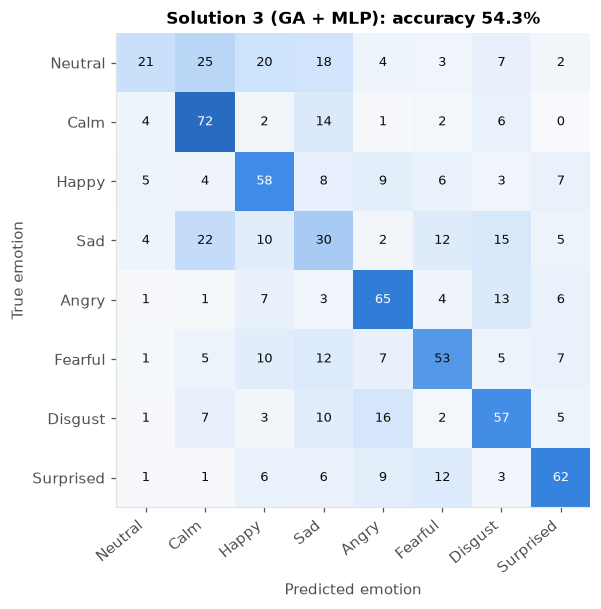

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
plot_confusion(s3.oof.y_true, s3.oof.y_pred, EMOTION_ORDER,
               f"Solution 3 (GA + MLP): accuracy {scores(s3.oof.y_true, s3.oof.y_pred)['accuracy']:.1%}", ax=ax)
save(fig, "10c_s3_confusion")
plt.show()

## 5. Which features did the GA keep?

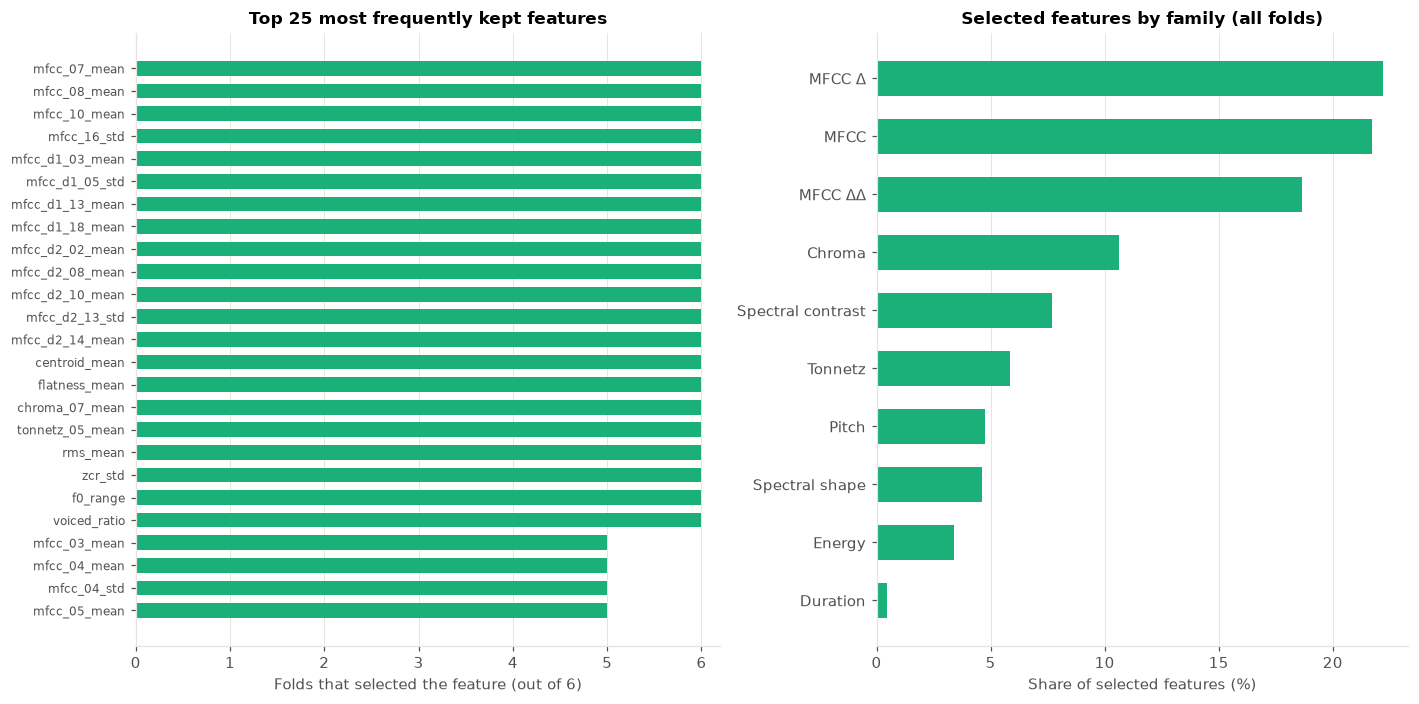

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
plot_selection_frequency(s3.selected, top=25, color=COLOR, title="Top 25 most frequently kept features", ax=axes[0])
fam = pd.Series([feature_group(f) for fold in s3.selected for f in fold]).value_counts(normalize=True) * 100
axes[1].barh(fam.index[::-1], fam.values[::-1], color=COLOR, height=0.6)
axes[1].set_xlabel("Share of selected features (%)")
axes[1].set_title("Selected features by family (all folds)")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "11c_s3_selected_features")
plt.show()

## 6. Summary

In [8]:
summary = pd.concat({"Baseline MLP (all 190)": base.summary(), "S3: GA + MLP": s3.summary()})
summary.round(3)

accuracy  macro_f1    uar  n_features  \
Baseline MLP (all 190) mean     0.533     0.473  0.503     190.000   
                       std      0.060     0.054  0.055       0.000   
S3: GA + MLP           mean     0.543     0.511  0.522     108.167   
                       std      0.072     0.077  0.071       5.845   

                             fit_seconds  
Baseline MLP (all 190) mean        1.338  
                       std         0.408  
S3: GA + MLP           mean        1.682  
                       std         0.529

In [9]:
d = s3.folds.macro_f1.mean() - base.folds.macro_f1.mean()
print(f"Macro-F1 change from feature selection: {d:+.3f}")
print(f"Features used: 190 -> {s3.folds.n_features.mean():.0f} on average")
print(f"Average GA time per outer fold: {s3.folds.select_seconds.mean() / 60:.1f} min")

Macro-F1 change from feature selection: +0.037
Features used: 190 -> 108 on average
Average GA time per outer fold: 10.8 min
